In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [201]:
"""
# 1. Dataset Exploration
# Load the dataset and explore its structure.
# Identify the target variable and potential features for linear regression.
"""
data = pd.read_csv('Expanded_data_with_more_features.csv')
data.drop(columns='Unnamed: 0', inplace=True) # not needed
data

# Targets: MathScore, ReadingScore, WritingScore

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,TransportMeans,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,female,NaN,bachelor's degree,standard,none,married,regularly,yes,3.0,school_bus,< 5,71,71,74
1,female,group C,some college,standard,NaN,married,sometimes,yes,0.0,NaN,5 - 10,69,90,88
2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,school_bus,< 5,87,93,91
3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,NaN,5 - 10,45,56,42
4,male,group C,some college,standard,none,married,sometimes,yes,0.0,school_bus,5 - 10,76,78,75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30636,female,group D,high school,standard,none,single,sometimes,no,2.0,school_bus,5 - 10,59,61,65
30637,male,group E,high school,standard,none,single,regularly,no,1.0,private,5 - 10,58,53,51
30638,female,NaN,high school,free/reduced,completed,married,sometimes,no,1.0,private,5 - 10,61,70,67
30639,female,group D,associate's degree,standard,completed,married,regularly,no,3.0,school_bus,5 - 10,82,90,93


In [202]:
"""
2. Data Preprocessing:
• Handle missing values: Decide on an appropriate strategy (imputation, removal, etc.).
• Explore and address outliers if present.
• Check for and handle any categorical features using encoding techniques.
"""

data.isna().sum() # checking missing data

Gender                    0
EthnicGroup            1840
ParentEduc             1845
LunchType                 0
TestPrep               1830
ParentMaritalStatus    1190
PracticeSport           631
IsFirstChild            904
NrSiblings             1572
TransportMeans         3134
WklyStudyHours          955
MathScore                 0
ReadingScore              0
WritingScore              0
dtype: int64

In [203]:
data.drop(columns='TransportMeans',inplace=True) # Too many missing 
data.isna().sum() # checking missing data

Gender                    0
EthnicGroup            1840
ParentEduc             1845
LunchType                 0
TestPrep               1830
ParentMaritalStatus    1190
PracticeSport           631
IsFirstChild            904
NrSiblings             1572
WklyStudyHours          955
MathScore                 0
ReadingScore              0
WritingScore              0
dtype: int64

In [204]:
# filling missing columns with mode
missing_cols = [
    'EthnicGroup', 'ParentEduc', 'TestPrep',
    'ParentMaritalStatus', 'PracticeSport', 'IsFirstChild',
    'NrSiblings', 'WklyStudyHours'
]
for col in missing_cols:
    mode = data[col].mode().iloc[0] # most repeated
    data[col] = data[col].fillna(mode)
    
data.isna().sum() # verfying no more missing

Gender                 0
EthnicGroup            0
ParentEduc             0
LunchType              0
TestPrep               0
ParentMaritalStatus    0
PracticeSport          0
IsFirstChild           0
NrSiblings             0
WklyStudyHours         0
MathScore              0
ReadingScore           0
WritingScore           0
dtype: int64

Index(['NrSiblings', 'MathScore', 'ReadingScore', 'WritingScore'], dtype='str')


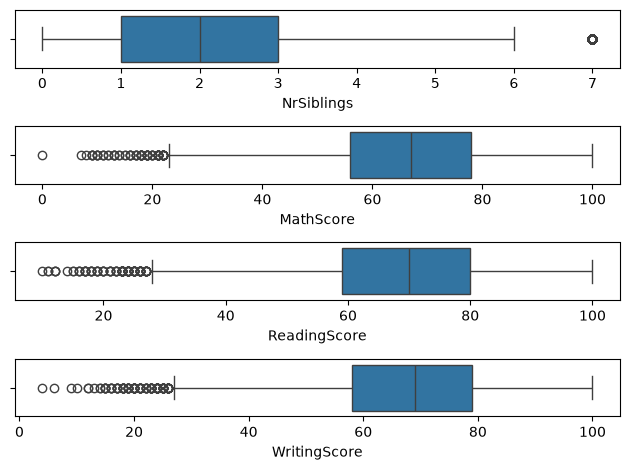

In [205]:
# checking outliers 
numeric_cols = data._get_numeric_data().columns
print(numeric_cols) # 4
fig, ax = plt.subplots(4,1)
for i, col in enumerate(numeric_cols):
    sns.boxplot(data=data, x=col, ax=ax[i])
    
fig.tight_layout()

In [206]:
print(len(data)) # before = 30641
for col in numeric_cols:
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1 
    lower_bound = q1 - (1.5*iqr)
    upper_bound = q3 + (1.5*iqr)
    data = data[(data[col] >= lower_bound) & (data[col] <= upper_bound )] # dropping


len(data) # after = 30185

30641


30185

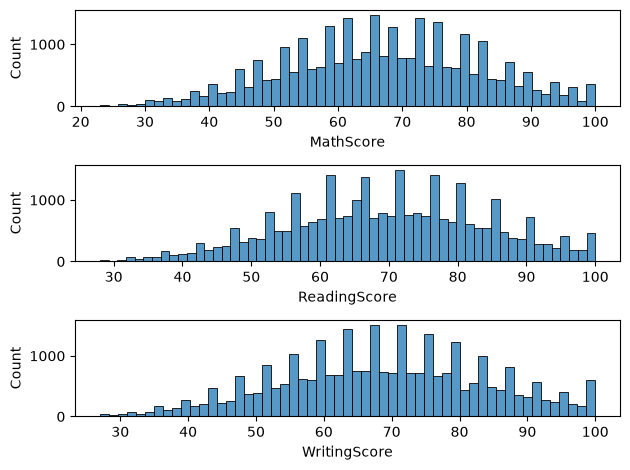

In [207]:
"""
3. Exploratory Data Analysis (EDA):
• Visualize the distribution of the target variable.
• Examine the relationships between features and the target through pair plots or
correlation matrices.
"""
fig , ax = plt.subplots(3,1)
# Targets: MathScore, ReadingScore, WritingScore
sns.histplot(data=data, x="MathScore", ax=ax[0])
sns.histplot(data=data, x="ReadingScore", ax=ax[1])
sns.histplot(data=data, x="WritingScore", ax=ax[2])
fig.tight_layout()

<Axes: >

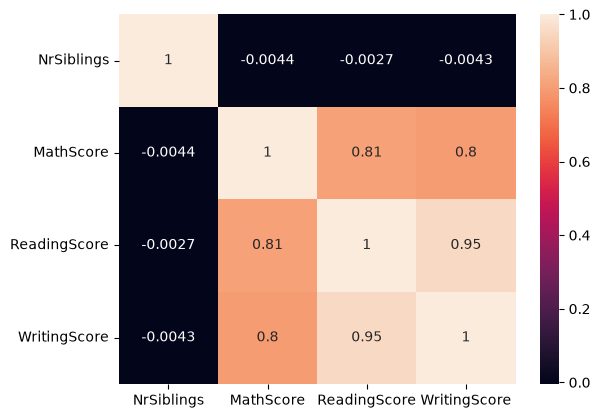

In [208]:
corr = data.select_dtypes(include="number").corr()

sns.heatmap(corr, annot=True)

In [227]:
"""
4. Feature Scaling:
• Apply feature scaling if needed to ensure that all features are on a similar scale.
"""
data
# I do not think it is needed, as numeric values are close in range

,Gender,EthnicGroup,ParentEduc,LunchType,TestPrep,ParentMaritalStatus,PracticeSport,IsFirstChild,NrSiblings,WklyStudyHours,MathScore,ReadingScore,WritingScore
0,female,group C,bachelor's degree,standard,none,married,regularly,yes,3.0,< 5,71,71,74
1,female,group C,some college,standard,none,married,sometimes,yes,0.0,5 - 10,69,90,88
2,female,group B,master's degree,standard,none,single,sometimes,yes,4.0,< 5,87,93,91
3,male,group A,associate's degree,free/reduced,none,married,never,no,1.0,5 - 10,45,56,42
4,male,group C,some college,standard,none,married,sometimes,yes,0.0,5 - 10,76,78,75
...,...,...,...,...,...,...,...,...,...,...,...,...,...
30636,female,group D,high school,standard,none,single,sometimes,no,2.0,5 - 10,59,61,65
30637,male,group E,high school,standard,none,single,regularly,no,1.0,5 - 10,58,53,51
30638,female,group C,high school,free/reduced,completed,married,sometimes,no,1.0,5 - 10,61,70,67
30639,female,group D,associate's degree,standard,completed,married,regularly,no,3.0,5 - 10,82,90,93


In [209]:
# Split before encoding to prevent data leakage 
"""
5. Train-Test Split:
• Split the dataset into training and testing sets.
"""
from sklearn.model_selection import train_test_split
target_cols = ['MathScore', 'ReadingScore', 'WritingScore']
features = data.drop(columns=target_cols)
targets = data[target_cols]

Xtrain, Xtest, ytrain, ytest = train_test_split(features, targets ,test_size=0.2, random_state=42)

print(Xtrain.shape)
print(Xtest.shape)
print(ytrain.shape)
print(ytest.shape)

(24148, 10)
(6037, 10)
(24148, 3)
(6037, 3)


In [210]:

# in task 3, Check for and handle any categorical features using encoding techniques.
categorical_cols = list(data.select_dtypes(exclude="number").columns)

for col in categorical_cols:
    print(f"{col}: {data[col].unique()}")

Gender: <StringArray>
['female', 'male']
Length: 2, dtype: str
EthnicGroup: <StringArray>
['group C', 'group B', 'group A', 'group D', 'group E']
Length: 5, dtype: str
ParentEduc: <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
LunchType: <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
TestPrep: <StringArray>
['none', 'completed']
Length: 2, dtype: str
ParentMaritalStatus: <StringArray>
['married', 'single', 'widowed', 'divorced']
Length: 4, dtype: str
PracticeSport: <StringArray>
['regularly', 'sometimes', 'never']
Length: 3, dtype: str
IsFirstChild: <StringArray>
['yes', 'no']
Length: 2, dtype: str
WklyStudyHours: <StringArray>
['< 5', '5 - 10', '> 10']
Length: 3, dtype: str


In [211]:
# for 2 cats. will use => label encoding
# rest will use one-hot encoding 
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
one_hot_encoder = OneHotEncoder(handle_unknown="ignore",
                sparse_output=False).set_output(transform="pandas")


cols_2 = ['Gender', 'TestPrep', 'IsFirstChild']
cols_more_than_2 = [col for col in categorical_cols if col not in cols_2]

print(cols_2)
print(cols_more_than_2)

['Gender', 'TestPrep', 'IsFirstChild']
['EthnicGroup', 'ParentEduc', 'LunchType', 'ParentMaritalStatus', 'PracticeSport', 'WklyStudyHours']


In [ ]:
# Encoding using one Hot
train_encoded = one_hot_encoder.fit_transform(Xtrain[cols_more_than_2])
test_encoded = one_hot_encoder.transform(Xtest[cols_more_than_2])
    
Xtrain = Xtrain.drop(columns=cols_more_than_2).join(train_encoded) # replace with encoded data
Xtest = Xtest.drop(columns=cols_more_than_2).join(test_encoded)

# Encoding using label
label_encoders = {}

for col in cols_2:
    encoder = LabelEncoder()

    Xtrain[col] = encoder.fit_transform(Xtrain[col])
    Xtest[col] = encoder.transform(Xtest[col])

    label_encoders[col] = encoder

In [216]:
"""
6. Linear Regression Model:
• Build a linear regression model using a suitable library (e.g., scikit-learn).
• Train the model on the training dataset.
"""
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(Xtrain, ytrain)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3, 27)","[[ 5.02,-4.33, 0.42,..., 0.24,-2.11, 1.87], [-6.93,-6.18, 0.44,..., 0.29,-1.21, 0.92], [-8.87,-9.02, 0.34,..., 0.2 ,-1.43, 1.23]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](27,)","['Gender','TestPrep','IsFirstChild',...,'WklyStudyHours_5 - 10', 'WklyStudyHours_< 5','WklyStudyHours_> 10']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](3,)","[66.11,76.6 ,78.44]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,27
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(21)


In [214]:
print(model.coef_) # weights of each feature
print(model.intercept_ )# bias (Base) 

[[ 5.02362768e+00 -4.32572149e+00  4.18466072e-01  1.45252107e-02
  -3.70780339e+00 -3.12914376e+00 -1.95044154e+00  5.92834020e-01
   8.19455467e+00  1.00895348e+00  2.79235952e+00 -2.89345959e+00
   5.17548194e+00 -1.21293985e+00 -4.87039551e+00 -5.80757561e+00
   5.80757561e+00  1.57008833e-01 -3.63839907e-02 -4.05218789e-01
   2.84593947e-01 -1.92465092e+00  1.74738697e+00  1.77263940e-01
   2.44534061e-01 -2.11193118e+00  1.86739712e+00]
 [-6.93083425e+00 -6.18109163e+00  4.36347406e-01  1.98379299e-02
  -2.36695210e+00 -2.07801299e+00 -8.80766723e-01  7.31549826e-01
   4.59418198e+00  1.00479434e+00  2.51790984e+00 -3.01463099e+00
   5.60446559e+00 -1.34825333e+00 -4.76428545e+00 -3.88465152e+00
   3.88465152e+00  8.35474239e-02  5.37314920e-02 -3.53650763e-01
   2.16371847e-01 -7.69976813e-01  7.62490654e-01  7.48615937e-03
   2.85268517e-01 -1.20762207e+00  9.22353556e-01]
 [-8.87322175e+00 -9.01779859e+00  3.41454342e-01  2.09818861e-02
  -2.83292424e+00 -2.40554204e+00 -1.178

In [217]:
"""
7. Model Evaluation:
• Evaluate the model's performance on the testing set.
• Use appropriate regression metrics (e.g., Mean Squared Error, R-squared).
"""
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ypred = model.predict(Xtest)
print("MAE:", mean_absolute_error(ytest, ypred))
print("MSE:", mean_squared_error(ytest, ypred))
print("R²:", r2_score(ytest, ypred))

MAE: 10.286217007107986
MSE: 158.2715526858509
R²: 0.2717256685692095


<Axes: xlabel='MathScore'>

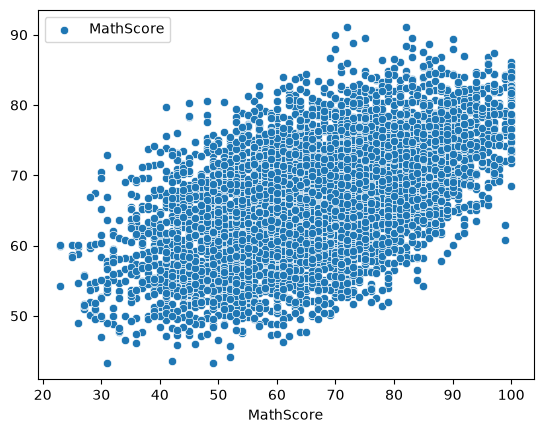

In [225]:
"""
8. Visualization:
• Visualize the predicted values against the actual values using scatter plots or regression
plots.
"""

sns.scatterplot(x=ytest['MathScore'], y=ypred[:,0], label='MathScore')


<Axes: xlabel='ReadingScore'>

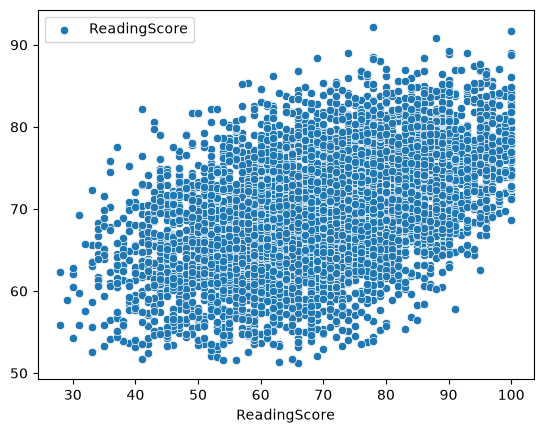

In [224]:
sns.scatterplot(x=ytest['ReadingScore'], y=ypred[:,1], label='ReadingScore')

<Axes: xlabel='WritingScore'>

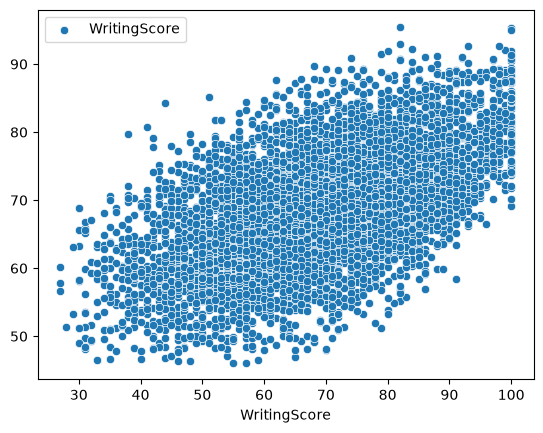

In [226]:
sns.scatterplot(x=ytest['WritingScore'], y=ypred[:,2], label='WritingScore')


In [ ]:
"""9. Conclusion:
• Summarize the findings from the linear regression task.
• Reflect on the model's performance and potential areas for improvement.
"""

# The linear regression model was trained on a dataset to predict three target variables: MathScore, ReadingScore, and WritingScore. 
# The model did not have perfect predictions, as indicated by the R² values,
#  Mean Absolute Error and Mean Squared Error metrics.
# I think this is because the dataset was broken , 
# containing alot of missing values and outliers, which were removed so led to data losses.
